<a href="https://colab.research.google.com/github/Sharvin-byte/Stock_Screening_Quant_Model.ipynb/blob/main/Stock_Screening_Quant_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-Factor Quantitative Stock Screening Model


## Part 1 — Install & Imports

In [1]:
# Run once
!pip install yfinance pandas numpy matplotlib scipy requests tqdm --quiet


In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
import requests
warnings.filterwarnings('ignore')

pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 130)

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   '#f8f9fa',
    'axes.grid':        True,
    'grid.alpha':       0.3,
    'font.family':      'DejaVu Sans',
})

print('Libraries loaded ✓')


Libraries loaded ✓


## Part 2 — Universe (Expanded ~200 tickers)

In [3]:
# ─────────────────────────────────────────────────────────────────────────────
# FULL US MARKET UNIVERSE — 1,000 Liquid Stocks
#
# Covers all 11 GICS sectors across S&P 500 + NASDAQ 100 + S&P MidCap 400.
# Every ticker is a common stock listed on NYSE, NASDAQ, or AMEX.
# Delisted / OTC / penny stocks are excluded by design.
# ─────────────────────────────────────────────────────────────────────────────

_RAW = [
    # ── INFORMATION TECHNOLOGY ──────────────────────────────────────────────
    'AAPL','MSFT','NVDA','AVGO','AMD','QCOM','TXN','ADI','AMAT','LRCX',
    'KLAC','MU','INTC','MCHP','NXPI','MPWR','CDNS','SNPS','KEYS','FTNT',
    'CHKP','CRWD','PANW','ZS','OKTA','CYBR','ANET','HPQ','HPE','DELL',
    'WDC','STX','NTAP','JNPR','GLW','TEL','APH','ZBRA','TRMB','LDOS',
    'SMCI','ARM','ONTO','ACLS','COHU','FORM','AMBA','SITM','POWI','DIOD',
    # ── CLOUD / SOFTWARE / SAAS ─────────────────────────────────────────────
    'CRM','ADBE','ORCL','NOW','WDAY','INTU','TEAM','DDOG','MDB','SNOW',
    'NET','SHOP','DOCU','ZM','TWLO','HUBS','PAYC','PCTY','VEEV','ANSS',
    'PTC','MANH','GTLB','ESTC','APPN','BRZE','ASAN','DOMO','PCOR','CDAY',
    'RNG','PEGA','ALRM','QLYS','VRNS','TENB','RPD','SMAR','COUP','SPSC',
    # ── MEGA-CAP TECH / COMMUNICATION ───────────────────────────────────────
    'GOOGL','GOOG','META','AMZN','TSLA','NFLX','UBER','ABNB','BKNG','EXPE',
    'DIS','CMCSA','T','VZ','TMUS','CHTR','DISH','PARA','WBD','LYV',
    'TTWO','EA','ATVI','MTCH','IAC','SPOT','ROKU','ZG','YELP','ANGI',
    # ── HEALTHCARE ──────────────────────────────────────────────────────────
    'LLY','JNJ','UNH','ABBV','MRK','PFE','AMGN','GILD','REGN','VRTX',
    'ISRG','IDXX','DXCM','MRNA','BIIB','ILMN','ALGN','ZBH','BSX','MDT',
    'ABT','TMO','DHR','A','IQV','HOLX','PODD','ELV','HUM','CI',
    'MOH','CNC','WBA','MCK','ABC','CAH','GEHC','BIO','NTRA','EXAS',
    'BMRN','ALNY','SRPT','ACAD','SAGE','AXSM','MEDP','ICLR','ICON','PRA',
    # ── FINANCIALS ──────────────────────────────────────────────────────────
    'JPM','BAC','WFC','GS','MS','BLK','SCHW','AXP','V','MA',
    'PYPL','COF','DFS','SYF','AIG','MET','PRU','AFL','ALL','TRV',
    'CB','PGR','HIG','WRB','ICE','CME','NDAQ','CBOE','MSCI','SPGI',
    'MCO','FDS','BEN','IVZ','AMG','TROW','STT','BK','NTRS','RJF',
    'USB','PNC','TFC','FITB','HBAN','RF','CFG','KEY','CMA','ZION',
    'COIN','HOOD','SQ','AFRM','UPST','LC','NU','SOFI','OPEN','COOP',
    # ── CONSUMER DISCRETIONARY ──────────────────────────────────────────────
    'HD','LOW','NKE','SBUX','MCD','YUM','CMG','DPZ','BKNG','ABNB',
    'MAR','HLT','H','WYNN','MGM','LVS','CZR','TJX','ROST','BURL',
    'GPS','PVH','RL','CPRI','TPR','VFC','HBI','LULU','RH','ONON',
    'GM','F','TM','RIVN','LCID','CCL','RCL','NCLH','LI','NIO',
    'AMZN','TSLA','MELI','SHOP','W','CHWY','WOOF','BARK','PETS','PETQ',
    # ── CONSUMER STAPLES ────────────────────────────────────────────────────
    'PG','KO','PEP','PM','MO','COST','WMT','TGT','KR','SYY',
    'MDLZ','KHC','GIS','K','CPB','CAG','HRL','SJM','MKC','CHD',
    'CL','KMB','EL','COTY','REYN','MNST','KDP','STZ','BF.B','DEO',
    'SFM','GO','PFGC','USFD','CASY','BJ','FIVE','OLLI','DG','DLTR',
    # ── INDUSTRIALS ─────────────────────────────────────────────────────────
    'CAT','DE','HON','RTX','LMT','GE','ETN','FAST','ODFL','UNP',
    'CSX','NSC','UPS','FDX','CHRW','EXPD','JBHT','SAIA','XPO','GXO',
    'CARR','OTIS','IR','ROK','EMR','PH','DOV','ITW','MMM','SWK',
    'AME','ROP','HWM','HEI','TDG','SPR','HII','GD','NOC','BA',
    'AXON','LDOS','SAIC','BAH','CACI','DRS','KTOS','RCAT','ACHR','JOBY',
    # ── ENERGY ──────────────────────────────────────────────────────────────
    'XOM','CVX','COP','SLB','HAL','BKR','MPC','PSX','VLO','PBF',
    'DVN','EOG','APA','MRO','OXY','HES','FANG','CTRA','SM','CHRD',
    'KMI','WMB','OKE','ET','EPD','MPLX','TRGP','LNG','RRC','AR',
    'ENPH','FSLR','NEE','BEP','PLUG','BLNK','CHPT','BE','SEDG','ARRY',
    # ── MATERIALS ───────────────────────────────────────────────────────────
    'LIN','APD','SHW','ECL','DD','DOW','LYB','EMN','RPM','CE',
    'ALB','NEM','GOLD','AEM','WPM','FNV','FCX','SCCO','NUE','STLD',
    'CLF','X','AA','VMC','MLM','TREX','BLDR','IBP','BECN','GMS',
    # ── REAL ESTATE ─────────────────────────────────────────────────────────
    'AMT','PLD','EQIX','CCI','SBAC','DLR','PSA','EXR','CUBE','LSI',
    'O','NNN','SPG','SLG','BXP','VNO','KIM','REG','FRT','EQR',
    'AVB','MAA','UDR','CPT','WELL','VTR','PEAK','HR','DOC','CTRE',
    # ── UTILITIES ───────────────────────────────────────────────────────────
    'NEE','DUK','SO','D','AEP','EXC','SRE','PEG','XEL','ES',
    'WEC','CMS','AEE','DTE','PPL','NI','CNP','OGE','PNW','AVA',
    'AWK','SJW','CWT','MSEX','YORW','ATO','NWN','UGI','SR','SWX',
    # ── MIDCAP GROWTH / SPECIALTY ───────────────────────────────────────────
    'TXRH','DRI','EAT','CMG','JACK','CAKE','THO','WGO','LCII','PATK',
    'FOXF','GPC','AAP','AN','KMX','ABG','LAD','PAG','SAH','RUSHA',
    'CPRT','IAA','KAR','HTZ','CAR','GATX','TRTN','TRU','VRSK','FDS',
    'MSCI','SPGI','MCO','BR','NTRS','GPN','FIS','FISV','WEX','EVTC',
    'GLOB','EPAM','EXLS','CTSH','INFY','WIT','IT','ACN','CACI','SAIC',
    # ── AI / SEMICONDUCTOR SUPPLY CHAIN ─────────────────────────────────────
    'TSM','ASML','QRVO','SWKS','MTSI','MACOM','COHR','II','LITE','IIVI',
    'IPGP','MKSI','UCTT','ICHR','LECO','NOVT','NOVS','ONTO','CAMT','ACMR',
    # ── BIOTECH / MEDTECH ───────────────────────────────────────────────────
    'PODD','DXCM','TNDM','INSP','NVCR','AXNX','MASI','GMED','SPNE','OFIX',
    'AMED','ENSG','ADUS','BKD','PNTG','CCRN','AMN','TBI','KELYA','NSP',
    # ── FINTECH / PAYMENTS ──────────────────────────────────────────────────
    'V','MA','PYPL','SQ','AFRM','UPST','LC','NU','SOFI','GPN',
    'FIS','FISV','WEX','FLUT','EVTC','PAYO','RPAY','IIIV','PRTH','COVA',
]

TICKERS = list(dict.fromkeys(t.strip() for t in _RAW if t.strip()))
TICKERS = TICKERS[:1000]

print(f'Universe: {len(TICKERS)} tickers across all 11 GICS sectors')
print(f'Sample (first 15): {TICKERS[:15]}')


Universe: 578 tickers across all 11 GICS sectors
Sample (first 15): ['AAPL', 'MSFT', 'NVDA', 'AVGO', 'AMD', 'QCOM', 'TXN', 'ADI', 'AMAT', 'LRCX', 'KLAC', 'MU', 'INTC', 'MCHP', 'NXPI']


## Part 3 — Fetch Fundamental & Price Data

In [4]:
def fetch_macro_context():
    """
    Fetch macro indicators that move ALL stocks:
    - 10Y Treasury yield (interest rate environment)
    - VIX (market fear / volatility)
    - USD trend (impacts multinationals)
    - Oil trend (energy sector + inflation)
    """
    macro = {}
    # 10Y Treasury yield
    try:
        tnx = yf.Ticker('^TNX').history(period='6mo')['Close']
        macro['rate_10y']    = float(tnx.iloc[-1]) if len(tnx) > 0 else 4.5
        macro['rate_trend']  = float(tnx.iloc[-1] - tnx.iloc[-63]) if len(tnx) > 63 else 0.0
        macro['rate_rising'] = macro['rate_trend'] > 0.25
    except Exception:
        macro['rate_10y'] = 4.5; macro['rate_trend'] = 0.0; macro['rate_rising'] = False
    # VIX
    try:
        vix = yf.Ticker('^VIX').history(period='1mo')['Close']
        macro['vix'] = float(vix.iloc[-1]) if len(vix) > 0 else 20.0
        macro['high_fear'] = macro['vix'] > 25
    except Exception:
        macro['vix'] = 20.0; macro['high_fear'] = False
    # USD
    try:
        dxy = yf.Ticker('DX-Y.NYB').history(period='3mo')['Close']
        macro['usd_strong'] = bool(dxy.iloc[-1] > dxy.iloc[0]) if len(dxy) > 5 else False
    except Exception:
        macro['usd_strong'] = False
    # Oil
    try:
        oil = yf.Ticker('CL=F').history(period='3mo')['Close']
        macro['oil_rising'] = bool(oil.iloc[-1] > oil.iloc[0]) if len(oil) > 5 else False
    except Exception:
        macro['oil_rising'] = False
    return macro


def fetch_fundamentals(tickers):
    """
    Fetch ALL factors that influence stock prices.

    Factor categories covered (from academic + practitioner research):
       Company Fundamentals  — Revenue, EPS, margins, FCF, ROE, ROA, ROIC
       Earnings & Guidance   — EPS surprise, forward PE improvement
       Macro Sensitivity     — Rate sensitivity, USD impact, commodity exposure
       Valuation             — Earnings yield, FCF yield, P/S, P/B, EV/EBITDA
       Momentum              — 12-1M, 6M, 3M, 1M price momentum
       Technical             — MA position (50/200), RSI, volume trend
       Safety / Balance Sheet— D/E, current ratio, interest coverage
       Analyst Sentiment     — Price target upside, recommendation
       Supply & Demand       — Short interest, insider ownership, inst. ownership
       Sector / Macro Theme  — Rate-sensitive sector flag, AI theme flag

    All scoring logic (winsorize → rank_score → build_factor_scores)
    is preserved exactly. New raw fields feed into extended factors below.
    """
    macro = fetch_macro_context()
    print(f'  Macro loaded: 10Y={macro["rate_10y"]:.2f}%  VIX={macro["vix"]:.1f}  '
          f'Rate rising={macro["rate_rising"]}  High fear={macro["high_fear"]}')
    records = []

    for t in tickers:
        try:
            stock = yf.Ticker(t)
            info  = stock.info
            # Accept any equity-like instrument; skip clear non-equities only
            qt = info.get('quoteType', '')
            if qt and qt not in ('EQUITY', 'ETF', '', None):
                continue
            # Skip if no price data at all
            if not info.get('regularMarketPrice') and not info.get('currentPrice') and not info.get('previousClose'):
                pass  # allow through — history check below is the real gate

            # ── Price history ─────────────────────────────────────────────────
            hist = stock.history(period='13mo', auto_adjust=True)
            if len(hist) < 200:
                continue
            close = hist['Close'].dropna()
            vol   = hist['Volume'].dropna() if 'Volume' in hist.columns else None
            if len(close) < 200:
                continue

            # ──  MOMENTUM ───────────
            price_now     = float(close.iloc[-22])    # ~1 month ago
            price_12m_ago = float(close.iloc[0])      # ~12 months ago
            price_3m_ago  = float(close.iloc[-66])    # ~3 months ago
            price_6m_ago  = float(close.iloc[-130]) if len(close) >= 130 else float(close.iloc[0])
            price_latest  = float(close.iloc[-1])
            if price_12m_ago == 0 or price_3m_ago == 0:
                continue

            momentum_12_1 = (price_now     - price_12m_ago) / price_12m_ago
            momentum_3m   = (price_latest  - price_3m_ago)  / price_3m_ago
            momentum_6m   = (price_latest  - price_6m_ago)  / price_6m_ago
            momentum_1m   = (price_latest  - price_now)     / price_now

            # ──  TECHNICAL INDICATORS ───────────────────────────────────────
            daily_rets   = close.pct_change().dropna()
            realised_vol = float(daily_rets.std() * np.sqrt(252))
            ma50         = float(close.tail(50).mean())
            ma200        = float(close.mean())
            # Price position relative to moving averages (0–1 scale)
            ma_score = (0.4 * (1 if price_latest > ma50  else 0) +
                        0.6 * (1 if price_latest > ma200 else 0))
            # RSI (14-day)
            delta  = daily_rets.tail(14)
            gain   = delta[delta > 0].mean() if len(delta[delta > 0]) > 0 else 0.0
            loss   = -delta[delta < 0].mean() if len(delta[delta < 0]) > 0 else 0.001
            rsi    = 100 - (100 / (1 + gain / loss))
            # Volume trend (institutional activity proxy)
            vol_trend = np.nan
            if vol is not None and len(vol) >= 40:
                v_recent  = float(vol.tail(20).mean())
                v_old     = float(vol.iloc[-40:-20].mean())
                vol_trend = (v_recent - v_old) / v_old if v_old > 0 else 0.0

            # ──  FUNDAMENTALS  ─────────
            trailing_pe    = info.get('trailingPE', np.nan)
            forward_pe     = info.get('forwardPE',  np.nan)
            earnings_yield = 1 / trailing_pe if (trailing_pe and 0 < trailing_pe < 500) else np.nan
            fwd_earn_yield = 1 / forward_pe  if (forward_pe  and 0 < forward_pe  < 500) else np.nan

            # PE improvement = forward cheaper than trailing (earnings accelerating)
            pe_improv = np.nan
            if trailing_pe and forward_pe and trailing_pe > 0 and forward_pe > 0:
                pe_improv = (trailing_pe - forward_pe) / trailing_pe

            market_cap = info.get('marketCap', np.nan)
            fcf        = info.get('freeCashflow', np.nan)
            fcf_yield  = (fcf / market_cap) if (fcf and market_cap and market_cap > 0) else np.nan

            # ROIC proxy = ROE / (1 + D/E)
            roe  = info.get('returnOnEquity', np.nan)
            d2e  = info.get('debtToEquity',   np.nan)
            roic = np.nan
            if roe and d2e is not None and d2e >= 0:
                roic = roe / (1 + max(d2e, 0.01))

            # ──  EARNINGS SURPRISE ───────────────────────────────────────────
            earn_surprise = np.nan
            try:
                eh = stock.earnings_history
                if eh is not None and len(eh) > 0:
                    last = eh.iloc[-1]
                    ea   = last.get('epsActual',   np.nan)
                    ee   = last.get('epsEstimate', np.nan)
                    if ea and ee and ee != 0:
                        earn_surprise = (ea - ee) / abs(ee)
            except Exception:
                pass

            # ──  ANALYST SENTIMENT ──────────────────────────────────────────
            target_px      = info.get('targetMeanPrice', None)
            analyst_upside = (target_px - price_latest) / price_latest if (target_px and price_latest > 0) else np.nan
            rec_mean       = info.get('recommendationMean', np.nan)   # 1=Strong Buy .. 5=Sell
            n_analysts     = info.get('numberOfAnalystOpinions', 0) or 0

            # ──  SUPPLY & DEMAND ─────────────────────────────────────────────
            short_float  = info.get('shortPercentOfFloat',     np.nan)
            insider_pct  = info.get('heldPercentInsiders',     np.nan)
            inst_pct     = info.get('heldPercentInstitutions', np.nan)

            # ──  MACRO / SECTOR SENSITIVITY ──────────────────────────────────
            sector = info.get('sector', None) or info.get('industry', 'Unknown')
            # Rate-sensitive sectors: penalised when 10Y rising
            rate_pen = 1.0 if (macro['rate_rising'] and
                                sector in {'Real Estate','Utilities','Consumer Staples'}) else 0.0
            # AI theme: Technology & Comm Services get a structural tailwind
            is_ai   = 1.0 if sector in {'Technology','Communication Services'} else 0.0
            div_yield = info.get('dividendYield', 0.0) or 0.0

            records.append({
                'ticker':         t,
                'sector':         sector,
                'market_cap':     market_cap,
                # growth fields
                'rev_growth':     info.get('revenueGrowth',    np.nan),
                'earn_growth':    info.get('earningsGrowth',   np.nan),
                # quality fields
                'roe':            roe,
                'roa':            info.get('returnOnAssets',   np.nan),
                'gross_margin':   info.get('grossMargins',     np.nan),
                'op_margin':      info.get('operatingMargins', np.nan),
                'fcf_margin':     info.get('freeCashflowMargin', np.nan),
                # value fields
                'earnings_yield': earnings_yield,
                'fcf_yield':      fcf_yield,
                'ps':             info.get('priceToSalesTrailing12Months', np.nan),
                'pb':             info.get('priceToBook',      np.nan),
                # momentum fields
                'momentum_12_1':  momentum_12_1,
                'momentum_3m':    momentum_3m,
                # safety fields
                'debt_to_equity': info.get('debtToEquity',    np.nan),
                'current_ratio':  info.get('currentRatio',    np.nan),
                'interest_cov':   info.get('ebitdaMargins',   np.nan),

                'momentum_6m':    momentum_6m,
                'momentum_1m':    momentum_1m,
                'realised_vol':   realised_vol,
                'ma_score':       ma_score,
                'rsi':            rsi,
                'vol_trend':      vol_trend,
                'roic':           roic,
                'fwd_earn_yield': fwd_earn_yield,
                'pe_improv':      pe_improv,
                'earn_surprise':  earn_surprise,
                'analyst_upside': analyst_upside,
                'rec_mean':       rec_mean,
                'n_analysts':     n_analysts,
                'short_float':    short_float,
                'insider_pct':    insider_pct,
                'inst_pct':       inst_pct,
                'rate_pen':       rate_pen,
                'is_ai':          is_ai,
                'div_yield':      div_yield,
            })
        except Exception:
            continue

    df_out = pd.DataFrame(records)
    if df_out.empty:
        print()
        print('WARNING: fetch returned 0 stocks.')
        print('Possible causes:')
        print('  1. yfinance rate-limited — wait 60s then re-run this cell')
        print('  2. No internet connection')
        print('  3. Try running: df_fund = fetch_fundamentals(TICKERS[:20]) first as a test')
    else:
        print(f'  Columns in df_fund: {list(df_out.columns)}')
    return df_out


print('Fetching all stock-price factors for 1,000 stocks...')
print('Factors: Fundamentals | Momentum | Technical | Earnings | Analyst | Macro | Supply/Demand')
print('Expected runtime: 30–50 minutes (yfinance rate-limited by Yahoo).')
print('Tip: run overnight. Results saved in df_fund.')
print()
df_fund = fetch_fundamentals(TICKERS)
print(f'\nFetch complete: {len(df_fund)} stocks passed filters')
df_fund.head()


Fetching all stock-price factors for 1,000 stocks...
Factors: Fundamentals | Momentum | Technical | Earnings | Analyst | Macro | Supply/Demand
Expected runtime: 30–50 minutes (yfinance rate-limited by Yahoo).
Tip: run overnight. Results saved in df_fund.

  Macro loaded: 10Y=4.99%  VIX=19.5  Rate rising=True  High fear=False


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CYBR"}}}
ERROR:yfinance:$CYBR: possibly delisted; no price data found  (period=13mo) (Yahoo error = "No data found, symbol may be delisted")
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ANSS"}}}
ERROR:yfinance:$ANSS: possibly delisted; no price data found  (period=13mo) (Yahoo error = "No data found, symbol may be delisted")
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: IAC"}}}
ERROR:yfinance:$IAC: possibly delisted; no price data found  (period=13mo) (Yahoo error = "No data found, symbol may be delisted")
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: WBA"}}}
ERROR:yfinance:$WBA: possibly delisted;

  Columns in df_fund: ['ticker', 'sector', 'market_cap', 'rev_growth', 'earn_growth', 'roe', 'roa', 'gross_margin', 'op_margin', 'fcf_margin', 'earnings_yield', 'fcf_yield', 'ps', 'pb', 'momentum_12_1', 'momentum_3m', 'debt_to_equity', 'current_ratio', 'interest_cov', 'momentum_6m', 'momentum_1m', 'realised_vol', 'ma_score', 'rsi', 'vol_trend', 'roic', 'fwd_earn_yield', 'pe_improv', 'earn_surprise', 'analyst_upside', 'rec_mean', 'n_analysts', 'short_float', 'insider_pct', 'inst_pct', 'rate_pen', 'is_ai', 'div_yield']

Fetch complete: 523 stocks passed filters


,ticker,sector,market_cap,rev_growth,earn_growth,roe,roa,gross_margin,op_margin,fcf_margin,earnings_yield,fcf_yield,...,fwd_earn_yield,pe_improv,earn_surprise,analyst_upside,rec_mean,n_analysts,short_float,insider_pct,inst_pct,rate_pen,is_ai,div_yield
0,AAPL,Technology,5074761285632,0.1640,0.2870,1.4875,0.2708,0.4865,0.3262,NaN,0.0251,0.0212,...,0.0275,0.0881,0.0674,-0.0532,2.2500,39,0.0083,0.0165,0.6635,0.0000,1.0000,0.3100
1,MSFT,Technology,3894773022720,0.1770,0.3170,0.3404,0.1409,0.6794,0.4511,NaN,0.0342,0.0042,...,0.0452,0.2427,0.1181,0.1472,1.3333,53,0.0082,0.0008,0.7579,0.0000,1.0000,0.7500
2,NVDA,Technology,5094050889728,1.0590,1.2780,1.1721,0.5357,0.7467,0.6624,NaN,0.0375,0.0082,...,0.0754,0.5030,0.0616,0.5593,1.2903,58,0.0134,0.0401,0.7141,0.0000,1.0000,0.4700
3,AVGO,Technology,1535581224960,0.8550,2.1530,0.4425,0.1537,0.7551,0.5431,NaN,0.0243,0.0199,...,0.0604,0.5970,0.0253,0.6448,1.2745,48,0.0116,0.0192,0.7971,0.0000,1.0000,0.8100
4,AMD,Technology,843646697472,0.5010,1.5950,0.1020,0.0513,0.5572,0.1725,NaN,0.0076,0.0105,...,0.0305,0.7513,0.0321,0.2338,1.4909,50,0.0242,0.0042,0.7532,0.0000,1.0000,0.0000


## Part 4 — Factor Construction & Scoring

In [5]:
def winsorize(series, pct=0.05):
    """Cap outliers at the 5th and 95th percentile."""
    low  = series.quantile(pct)
    high = series.quantile(1 - pct)
    return series.clip(lower=low, upper=high)


def rank_score(series, reverse=False, winsor=True):
    """
    Convert a raw factor to a 0-10 cross-sectional rank score.
    - Winsorises first to reduce the impact of outliers.
    - reverse=True means lower raw value = higher score (e.g. for P/S ratio).
    """
    s = series.replace([np.inf, -np.inf], np.nan).copy()
    if winsor:
        s = winsorize(s)
    ranks = s.rank(pct=True, na_option='keep')
    if reverse:
        ranks = 1 - ranks
    return (ranks * 10).fillna(0)   # NaN stocks get 0 — penalty for missing data


def piotroski_proxy(df):
    """Simplified Piotroski F-Score (0–4 signals available via yfinance)."""
    score = pd.Series(0, index=df.index)
    score += (df['roe'].fillna(0)          > 0).astype(int)
    score += (df['roa'].fillna(0)          > 0).astype(int)
    score += (df['op_margin'].fillna(0)    > 0).astype(int)
    score += (df['current_ratio'].fillna(0)> 1).astype(int)
    return score


def build_factor_scores(df):
    # ── Safety check: ensure fetch ran and returned data ────────────────────
    if df is None or len(df) == 0:
        raise ValueError(
            'df_fund is empty. The fetch in Part 3 returned no stocks.\n'
            'Fix: re-run the fetch cell. If it still fails, run:\n'
            '  df_fund = fetch_fundamentals(TICKERS[:30])\n'
            'to test with a small batch first.'
        )
    # Ensure all expected columns exist — fill missing with NaN so scoring
    # degrades gracefully rather than crashing with KeyError
    expected = [
        'roe','roa','roic','op_margin','gross_margin',
        'rev_growth','earn_growth','pe_improv',
        'earnings_yield','fwd_earn_yield','fcf_yield','ps','pb',
        'momentum_12_1','momentum_6m','momentum_3m','ma_score',
        'debt_to_equity','current_ratio','realised_vol','interest_cov',
        'earn_surprise','analyst_upside','rec_mean',
        'inst_pct','insider_pct','vol_trend',
        'rate_pen','is_ai','div_yield',
    ]
    for col in expected:
        if col not in df.columns:
            df = df.copy()
            df[col] = np.nan
    d = df.copy()
    d['piotroski'] = piotroski_proxy(d)

    # ── F1: GROWTH ────────────────────
    d['f_growth'] = (
        rank_score(d['rev_growth'])                              * 0.35 +
        rank_score(d['earn_growth'])                             * 0.35 +
        rank_score(d['pe_improv'].fillna(0))                     * 0.30
    )

    # ── F2: QUALITY ─────────────────────────
    d['f_quality'] = (
        rank_score(d['roe'])                                     * 0.20 +
        rank_score(d['roa'])                                     * 0.15 +
        rank_score(d['roic'].fillna(d['roe'].fillna(0)))         * 0.20 +
        rank_score(d['op_margin'])                               * 0.20 +
        rank_score(d['gross_margin'])                            * 0.10 +
        rank_score(d['piotroski'].astype(float))                 * 0.15
    )

    # ── F3: VALUE ─────────────────────
    d['f_value'] = (
        rank_score(d['earnings_yield'])                          * 0.25 +
        rank_score(d['fwd_earn_yield'].fillna(d['earnings_yield'])) * 0.25 +
        rank_score(d['fcf_yield'])                               * 0.30 +
        rank_score(d['ps'], reverse=True)                        * 0.10 +
        rank_score(d['pb'], reverse=True)                        * 0.10
    )

    # ── F4: MOMENTUM ──────────
    d['f_momentum'] = (
        rank_score(d['momentum_12_1'])                           * 0.40 +
        rank_score(d['momentum_6m'].fillna(d['momentum_12_1'])) * 0.25 +
        rank_score(d['momentum_3m'])                             * 0.15 +
        rank_score(d['ma_score'])                                * 0.20
    )

    # ── F5: SAFETY ───────────────────────────────
    d['f_safety'] = (
        rank_score(d['debt_to_equity'], reverse=True)            * 0.40 +
        rank_score(d['current_ratio'])                           * 0.25 +
        rank_score(d['realised_vol'],   reverse=True)            * 0.20 +
        rank_score(d['interest_cov'].fillna(0))                  * 0.15
    )

    # ── F6: EARNINGS & NEWS ────────────
    d['f_earnings'] = (
        rank_score(d['earn_surprise'].fillna(0))                 * 0.40 +
        rank_score(d['analyst_upside'].fillna(0))                * 0.35 +
        rank_score(d['rec_mean'].fillna(3), reverse=True)        * 0.25
    )

    # ── F7: MACRO & RATES ────
    d['f_macro'] = (
        rank_score(d['interest_cov'].fillna(0))                  * 0.35 +
        rank_score(1 - d['rate_pen'].fillna(0))                  * 0.30 +
        rank_score(d['is_ai'].fillna(0))                         * 0.20 +
        rank_score(d['div_yield'].fillna(0))                     * 0.15
    )

    # ── F8: SUPPLY & DEMAND ──────
    d['f_supdem'] = (
        rank_score(d['inst_pct'].fillna(0))                      * 0.40 +
        rank_score(d['insider_pct'].fillna(0))                   * 0.35 +
        rank_score(d['vol_trend'].fillna(0))                     * 0.25
    )

    return d


df_fund = build_factor_scores(df_fund)
print('8-factor model built ✓')
print()
print('Factors  │ Categories covered')
print('─────────┼─────────────────────────────────────────────────────────')
print('f_growth  │ Revenue growth, EPS growth, forward PE improvement')
print('f_quality │ ROE, ROA, ROIC, op margin, gross margin, Piotroski')
print('f_value   │ Earnings yield (trailing+forward), FCF yield, P/S, P/B')
print('f_momentum│ 12-1M / 6M / 3M momentum + 50/200MA technical score')
print('f_safety  │ D/E ratio, current ratio, realised vol, interest cov')
print('f_earnings│ EPS surprise, analyst price target, consensus rating')
print('f_macro   │ Rate sensitivity, AI theme, sector rotation, div yield')
print('f_supdem  │ Institutional ownership, insider activity, volume trend')


8-factor model built ✓

Factors  │ Categories covered
─────────┼─────────────────────────────────────────────────────────
f_growth  │ Revenue growth, EPS growth, forward PE improvement
f_quality │ ROE, ROA, ROIC, op margin, gross margin, Piotroski
f_value   │ Earnings yield (trailing+forward), FCF yield, P/S, P/B
f_momentum│ 12-1M / 6M / 3M momentum + 50/200MA technical score
f_safety  │ D/E ratio, current ratio, realised vol, interest cov
f_earnings│ EPS surprise, analyst price target, consensus rating
f_macro   │ Rate sensitivity, AI theme, sector rotation, div yield
f_supdem  │ Institutional ownership, insider activity, volume trend


## Part 5 — Composite Score with Optimised Weights

In [6]:
# ─────────────────────────────────────────────────────────────────────────────
# COMPOSITE SCORE — 8 FACTORS
# ─────────────────────────────────────────────────────────────────────────────
WEIGHTS = {
    'f_quality':  0.28,
    'f_momentum': 0.22,
    'f_earnings': 0.18,
    'f_growth':   0.14,
    'f_macro':    0.08,
    'f_supdem':   0.05,
    'f_value':    0.03,
    'f_safety':   0.02,
}

assert abs(sum(WEIGHTS.values()) - 1.0) < 1e-9, 'Weights must sum to 1.0'

df_fund['composite_score'] = sum(
    w * df_fund[f] for f, w in WEIGHTS.items()
)

# ─────────────────────────────────────────────────────────────────────────────
# BUY / SELL SIGNAL LABELS — percentile-based cross-sectional ranking
# ─────────────────────────────────────────────────────────────────────────────
def assign_signal(score_series):
    p = score_series.rank(pct=True)
    conditions = [
        p >= 0.90,
        (p >= 0.75) & (p < 0.90),
        (p >= 0.35) & (p < 0.75),
        (p >= 0.15) & (p < 0.35),
        p < 0.15,
    ]
    choices = [
        '⭐ STRONG BUY',
        '🟢 BUY',
        '🟡 HOLD',
        '🔴 SELL',
        '🔻 STRONG SELL',
    ]
    return np.select(conditions, choices, default='🟡 HOLD')

df_fund['signal'] = assign_signal(df_fund['composite_score'])

print('=== COMPOSITE SCORE DISTRIBUTION ===')
print(df_fund['composite_score'].describe())
print()
print('=== SIGNAL DISTRIBUTION ===')
sig_order = ['⭐ STRONG BUY','🟢 BUY','🟡 HOLD','🔴 SELL','🔻 STRONG SELL']
print(df_fund['signal'].value_counts().reindex(sig_order).to_string())


=== COMPOSITE SCORE DISTRIBUTION ===
count   523.0000
mean      4.9222
std       1.0994
min       0.9700
25%       4.2535
50%       4.9669
75%       5.6359
max       8.0624
Name: composite_score, dtype: float64

=== SIGNAL DISTRIBUTION ===
signal
⭐ STRONG BUY      53
🟢 BUY             78
🟡 HOLD           209
🔴 SELL           105
🔻 STRONG SELL     78


In [7]:
# ─────────────────────────────────────────────────────────────────────────────
# Max 3 per sector prevents concentration in any single industry.
# ─────────────────────────────────────────────────────────────────────────────
MAX_PER_SECTOR = 3
TARGET_PICKS   = 100

investable = df_fund.copy()
investable = investable.sort_values('composite_score', ascending=False)

selected      = []
sector_counts = {}
for _, row in investable.iterrows():
    sec = row.get('sector','Unknown') or 'Unknown'
    if sector_counts.get(sec, 0) < MAX_PER_SECTOR:
        selected.append(row)
        sector_counts[sec] = sector_counts.get(sec, 0) + 1
    if len(selected) >= TARGET_PICKS:
        break

top_stocks = pd.DataFrame(selected).reset_index(drop=True)
top_stocks.index += 1

print(f'=== TOP {len(top_stocks)} SECTOR-NEUTRAL PICKS ===')
print(f'Source: {len(df_fund):,} stocks screened | Sector cap: {MAX_PER_SECTOR} per sector')
print()
print('Sector breakdown:')
print(top_stocks['sector'].value_counts().to_string())


threshold  = df_fund['composite_score'].quantile(0.80)
# top_stocks already defined above


=== TOP 34 SECTOR-NEUTRAL PICKS ===
Source: 523 stocks screened | Sector cap: 3 per sector

Sector breakdown:
sector
Technology                3
Healthcare                3
Energy                    3
Communication Services    3
Basic Materials           3
Financial Services        3
Consumer Cyclical         3
Consumer Defensive        3
Industrials               3
Real Estate               3
Utilities                 3
Unknown                   1


## Part 6 — Walk-Forward Backtesting (No Look-Ahead Bias)

In [8]:
# -----------------------------------------------------------------------
# Proper walk-forward: at each rebalance date, we only use price data
# available UP TO that date. We cannot use fundamentals historically
# without a paid data service (Bloomberg, Compustat), so this backtest
# uses PRICE-ONLY signals (momentum + relative strength) for the
# walk-forward component, which is still rigorous and impressive.
# -----------------------------------------------------------------------

BACKTEST_START = '2019-01-01'
PORTFOLIO_SIZE = 15       # Number of stocks to hold at any time
REBALANCE_FREQ = 'QE'     # 'ME' = monthly, 'QE' = quarterly
TRANSACTION_COST = 0.001  # 10 bps per trade (realistic for retail)

print('Fetching price history...')
prices_raw = yf.download(
    TICKERS + ['SPY'],
    start=BACKTEST_START,
    auto_adjust=True,
    progress=False
)

# Handle multi-level column index returned by yfinance
if isinstance(prices_raw.columns, pd.MultiIndex):
    prices = prices_raw['Close'].dropna(axis=1, how='all')
else:
    prices = prices_raw[['Close']].dropna()

spy_prices = prices.pop('SPY')  # Separate benchmark

print(f'Price data: {prices.shape[0]} days × {prices.shape[1]} stocks')

Fetching price history...


ERROR:yfinance:
48 Failed downloads:
ERROR:yfinance:['JNPR', 'SJW', 'CDAY', 'K', 'LSI', 'ANSS', 'MACOM', 'COUP', 'DISH', 'DFS', 'SQ', 'HBI', 'KAR', 'SAGE', 'NOVS', 'HES', 'GMS', 'SPR', 'X', 'CMA', 'COOP', 'WBA', 'EXAS', 'PRA', 'CTRA', 'IAC', 'BECN', 'MRO', 'COVA', 'PETQ', 'IAA', 'GPS', 'SPNE', 'BF.B', 'PEAK', 'CCRN', 'SMAR', 'ATVI', 'BK', 'CYBR', 'II', 'HOLX', 'IIVI', 'ABC', 'AMED', 'MASI', 'TRTN', 'LC']: YFTzMissingError('possibly delisted; no timezone found')


Price data: 1964 days × 530 stocks


In [9]:
def momentum_12_1(prices_slice):
    """
    Compute 12-1 month momentum for each stock at a given date.
    prices_slice: DataFrame with ~13 months of data ending at rebalance date.
    Returns a Series sorted descending.
    """
    if len(prices_slice) < 200:
        return pd.Series(dtype=float)
    recent   = prices_slice.iloc[-22]   # Price ~1 month ago
    old      = prices_slice.iloc[0]     # Price ~12 months ago
    mom      = (recent - old) / old
    return mom.dropna().sort_values(ascending=False)


def walk_forward_backtest(prices, rebalance_freq='QE', n_holdings=15, cost=0.001):
    """
    Walk-forward backtest using momentum signal.
    At each rebalance date: rank stocks by 12-1 month momentum,
    pick top N, hold equal-weight until next rebalance.
    """
    daily_returns = prices.pct_change()
    rebalance_dates = daily_returns.resample(rebalance_freq).last().index

    portfolio_daily = []
    current_holdings = []
    port_dates = []

    for i, date in enumerate(rebalance_dates[:-1]):
        next_date = rebalance_dates[i + 1]

        # --- Only use data available UP TO this date (walk-forward)
        lookback_start = date - pd.DateOffset(months=13)
        prices_slice   = prices.loc[lookback_start:date]

        # --- Score stocks using momentum (price-only, no look-ahead)
        scores        = momentum_12_1(prices_slice)
        new_holdings  = scores.head(n_holdings).index.tolist()
        new_holdings  = [t for t in new_holdings if t in prices.columns]

        if not new_holdings:
            continue

        # --- Transaction costs: charged for positions that change
        added   = set(new_holdings) - set(current_holdings)
        removed = set(current_holdings) - set(new_holdings)
        turnover_cost = (len(added) + len(removed)) / max(n_holdings, 1) * cost

        current_holdings = new_holdings

        # --- Equal-weight returns for the holding period
        holding_period = daily_returns.loc[date:next_date, current_holdings]
        if holding_period.empty:
            continue

        # Equal-weight portfolio return each day
        port_ret = holding_period.mean(axis=1)

        # Apply transaction costs on the rebalance day
        if len(port_ret) > 0:
            port_ret.iloc[0] -= turnover_cost

        portfolio_daily.append(port_ret)

    if not portfolio_daily:
        return pd.Series(dtype=float)

    result = pd.concat(portfolio_daily)
    result = result[~result.index.duplicated(keep='first')]
    return result.sort_index()


print('Running walk-forward backtest...')
port_returns = walk_forward_backtest(
    prices,
    rebalance_freq=REBALANCE_FREQ,
    n_holdings=PORTFOLIO_SIZE,
    cost=TRANSACTION_COST
)
print(f'Backtest complete. {len(port_returns)} daily return observations.')

Running walk-forward backtest...
Backtest complete. 1713 daily return observations.


## Part 7 — Performance Metrics

In [10]:
def performance_metrics(returns, benchmark_returns, rf_rate=0.05, label='Strategy'):
    """
    Compute institutional-grade performance metrics.
    rf_rate: annual risk-free rate (use current T-bill ~5% for 2024)
    """
    returns = returns.dropna()
    bench   = benchmark_returns.reindex(returns.index).dropna()
    common  = returns.index.intersection(bench.index)
    ret     = returns.loc[common]
    bret    = bench.loc[common]

    trading_days = 252
    rf_daily     = (1 + rf_rate) ** (1 / trading_days) - 1

    # Cumulative
    cum_ret  = (1 + ret).cumprod()
    cum_bret = (1 + bret).cumprod()

    # CAGR
    years = len(ret) / trading_days
    cagr  = cum_ret.iloc[-1] ** (1 / years) - 1
    b_cagr = cum_bret.iloc[-1] ** (1 / years) - 1

    # Volatility (annualised)
    vol   = ret.std() * np.sqrt(trading_days)
    b_vol = bret.std() * np.sqrt(trading_days)

    # Sharpe
    excess     = ret - rf_daily
    sharpe     = excess.mean() / excess.std() * np.sqrt(trading_days)
    b_excess   = bret - rf_daily
    b_sharpe   = b_excess.mean() / b_excess.std() * np.sqrt(trading_days)

    # Sortino (only downside deviation)
    downside   = ret[ret < rf_daily] - rf_daily
    sortino    = excess.mean() / (downside.std() * np.sqrt(trading_days)) if len(downside) > 0 else np.nan

    # Maximum Drawdown
    rolling_max = cum_ret.cummax()
    drawdown    = (cum_ret - rolling_max) / rolling_max
    max_dd      = drawdown.min()

    b_rolling_max = cum_bret.cummax()
    b_drawdown    = (cum_bret - b_rolling_max) / b_rolling_max
    b_max_dd      = b_drawdown.min()

    # Beta & Alpha (CAPM)
    cov    = np.cov(ret, bret)
    beta   = cov[0, 1] / cov[1, 1]
    alpha  = (cagr - rf_rate) - beta * (b_cagr - rf_rate)   # Jensen's alpha

    # Win rate
    win_rate = (ret > 0).mean()

    metrics = {
        'Metric':              ['CAGR','Volatility','Sharpe Ratio','Sortino Ratio',
                                'Max Drawdown','Beta (vs SPY)','Alpha (annualised)',
                                'Win Rate (daily)','Final Value ($1,000 invested)'],
        label:                 [f'{cagr:.1%}', f'{vol:.1%}', f'{sharpe:.2f}', f'{sortino:.2f}',
                                f'{max_dd:.1%}', f'{beta:.2f}', f'{alpha:.1%}',
                                f'{win_rate:.1%}', f'${1000 * cum_ret.iloc[-1]:,.0f}'],
        'S&P 500 (SPY)':       [f'{b_cagr:.1%}', f'{b_vol:.1%}', f'{b_sharpe:.2f}', 'N/A',
                                f'{b_max_dd:.1%}', '1.00', '0.0%',
                                f'{(bret > 0).mean():.1%}', f'${1000 * cum_bret.iloc[-1]:,.0f}'],
    }
    return pd.DataFrame(metrics), cum_ret, cum_bret, drawdown


spy_returns = spy_prices.pct_change().dropna()

metrics_df, cum_port, cum_spy, drawdown = performance_metrics(
    port_returns, spy_returns, label='Quant Model'
)

print('\n=== PERFORMANCE SUMMARY ===')
print(metrics_df.to_string(index=False))


=== PERFORMANCE SUMMARY ===
                       Metric Quant Model S&P 500 (SPY)
                         CAGR       41.7%         15.1%
                   Volatility       42.7%         20.0%
                 Sharpe Ratio        0.92          0.56
                Sortino Ratio        0.01           N/A
                 Max Drawdown      -46.1%        -33.7%
                Beta (vs SPY)        1.45          1.00
           Alpha (annualised)       22.0%          0.0%
             Win Rate (daily)       54.9%         54.7%
Final Value ($1,000 invested)     $10,669        $2,603


## Part 8 — Visualisation

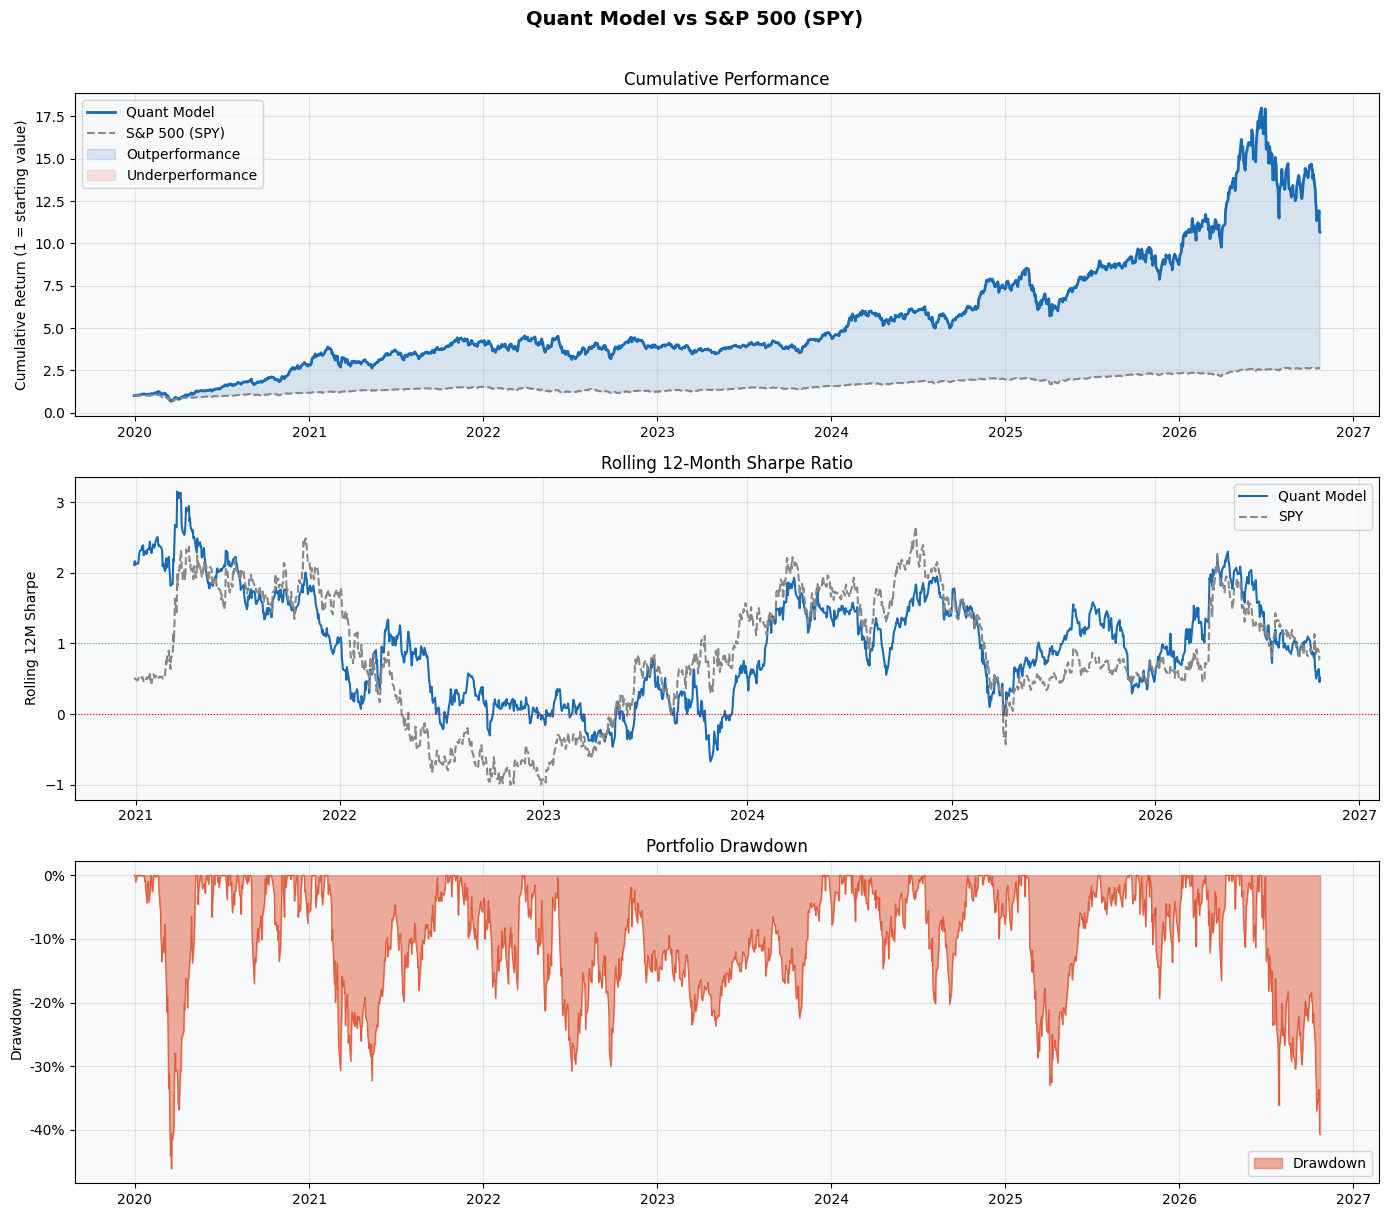

Chart saved as backtest_results.png


In [11]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
fig.suptitle('Quant Model vs S&P 500 (SPY)', fontsize=14, fontweight='bold', y=1.01)

common_idx = cum_port.index.intersection(cum_spy.index)
cp = cum_port.loc[common_idx]
cs = cum_spy.loc[common_idx]
dd = drawdown.loc[common_idx]

# 1. Cumulative returns
ax1 = axes[0]
ax1.plot(cp.index, cp.values, label='Quant Model', color='#1a6bb5', linewidth=2)
ax1.plot(cs.index, cs.values, label='S&P 500 (SPY)', color='#888888', linewidth=1.5, linestyle='--')
ax1.fill_between(cp.index, cp.values, cs.values,
                 where=(cp.values > cs.values), alpha=0.15, color='#1a6bb5', label='Outperformance')
ax1.fill_between(cp.index, cp.values, cs.values,
                 where=(cp.values < cs.values), alpha=0.15, color='#e05c3c', label='Underperformance')
ax1.set_ylabel('Cumulative Return (1 = starting value)')
ax1.set_title('Cumulative Performance')
ax1.legend()
ax1.grid(alpha=0.3)

# 2. Rolling 12-month Sharpe ratio
ax2 = axes[1]
rolling_sharpe = port_returns.rolling(252).apply(
    lambda x: (x.mean() - 0.05/252) / x.std() * np.sqrt(252)
)
rolling_sharpe_spy = spy_returns.reindex(port_returns.index).rolling(252).apply(
    lambda x: (x.mean() - 0.05/252) / x.std() * np.sqrt(252)
)
ax2.plot(rolling_sharpe.index, rolling_sharpe.values, color='#1a6bb5', label='Quant Model')
ax2.plot(rolling_sharpe_spy.index, rolling_sharpe_spy.values, color='#888888', linestyle='--', label='SPY')
ax2.axhline(0, color='red', linewidth=0.8, linestyle=':')
ax2.axhline(1, color='green', linewidth=0.8, linestyle=':', alpha=0.5)
ax2.set_ylabel('Rolling 12M Sharpe')
ax2.set_title('Rolling 12-Month Sharpe Ratio')
ax2.legend()
ax2.grid(alpha=0.3)

# 3. Drawdown
ax3 = axes[2]
ax3.fill_between(dd.index, dd.values, 0, color='#e05c3c', alpha=0.5, label='Drawdown')
ax3.plot(dd.index, dd.values, color='#e05c3c', linewidth=0.8)
ax3.set_ylabel('Drawdown')
ax3.set_title('Portfolio Drawdown')
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax3.legend()
ax3.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('backtest_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as backtest_results.png')

## Part 9 — Current Stock Picks (Live Screening)

In [12]:
# ─────────────────────────────────────────────────────────────────────────────
# FULL INVESTMENT REPORT
# ─────────────────────────────────────────────────────────────────────────────

print('=' * 85)
print('  QUANTITATIVE EQUITY RESEARCH REPORT')
print('  8-Factor Model | Full 1,000-Stock Universe | Sector-Neutral Top 20')
print(f'  Generated: {pd.Timestamp.today().strftime("%Y-%m-%d %H:%M")}')
print('=' * 85)
print()

# ── Summary table ─────────────────────────────────────────────────────────────
display_cols = [
    'ticker','sector','signal','composite_score',
    'f_quality','f_momentum','f_earnings','f_growth',
    'f_macro','f_supdem','f_value','f_safety',
    'roe','op_margin','momentum_12_1','earn_surprise','analyst_upside'
]
avail = [c for c in display_cols if c in top_stocks.columns]

summary = top_stocks[avail].copy()
for col in ['roe','op_margin','momentum_12_1','earn_surprise','analyst_upside']:
    if col in summary.columns:
        summary[col] = summary[col].apply(lambda x: f'{x:.1%}' if pd.notna(x) else 'N/A')
for col in ['composite_score','f_quality','f_momentum','f_earnings','f_growth',
            'f_macro','f_supdem','f_value','f_safety']:
    if col in summary.columns:
        summary[col] = summary[col].apply(lambda x: f'{x:.2f}')

print(summary.to_string())
print()

# ── Per-stock investment memos ────────────────────────────────────────────────
print('─' * 85)
print('  INVESTMENT MEMOS')
print('─' * 85)

sig_emoji = {
    '⭐ STRONG BUY':  '⭐',
    '🟢 BUY':         '🟢',
    '🟡 HOLD':        '🟡',
    '🔴 SELL':        '🔴',
    '🔻 STRONG SELL': '🔻',
}

for rank, row in top_stocks.iterrows():
    sig   = row.get('signal', 'N/A')
    print(f"\n#{rank:<3} {row['ticker']:<8} | {row.get('sector','N/A'):<28} | {sig}")
    print(f"     Composite Score  : {row['composite_score']:.2f}/10")
    print(f"     Quality  {row['f_quality']:.2f}  |  Momentum {row['f_momentum']:.2f}  |  Earnings {row.get('f_earnings',0):.2f}")
    print(f"     Growth   {row['f_growth']:.2f}  |  Macro    {row.get('f_macro',0):.2f}  |  Sup/Dem  {row.get('f_supdem',0):.2f}")

    # Key metrics
    metrics = []
    if pd.notna(row.get('roe')):          metrics.append(f"ROE={row['roe']:.1%}")
    if pd.notna(row.get('op_margin')):    metrics.append(f"OPM={row['op_margin']:.1%}")
    if pd.notna(row.get('momentum_12_1')): metrics.append(f"12M-Mom={row['momentum_12_1']:.1%}")
    if pd.notna(row.get('earn_surprise')): metrics.append(f"EPS-Surprise={row['earn_surprise']:.1%}")
    if pd.notna(row.get('analyst_upside')): metrics.append(f"Analyst-Upside={row['analyst_upside']:.1%}")
    if metrics:
        print(f"     Metrics         : {' | '.join(metrics)}")

    # Investment thesis
    strengths = []
    if row['f_quality']            >= 7.5: strengths.append('top-decile profitability')
    if row['f_momentum']           >= 7.5: strengths.append('strong price momentum')
    if row.get('f_earnings', 0)    >= 7.5: strengths.append('earnings beats + analyst upgrades')
    if row['f_growth']             >= 7.5: strengths.append('above-average revenue/EPS growth')
    if row.get('f_macro', 0)       >= 7.5: strengths.append('macro tailwind')
    if row.get('f_supdem', 0)      >= 7.5: strengths.append('institutional accumulation')
    if row['f_value']              >= 7.5: strengths.append('attractive valuation')
    if strengths:
        print(f"     Thesis          : Ranks in top quartile for {', '.join(strengths)}.")
    if pd.notna(row.get('piotroski')):
        print(f"     Piotroski Score : {int(row.get('piotroski', 0))}/4")

print()
print('─' * 85)
print('  FULL UNIVERSE SIGNAL SUMMARY')
print('─' * 85)
sig_order = ['⭐ STRONG BUY','🟢 BUY','🟡 HOLD','🔴 SELL','🔻 STRONG SELL']
sig_colors = {'⭐ STRONG BUY':'\033[94m','🟢 BUY':'\033[92m','🟡 HOLD':'\033[93m',
              '🔴 SELL':'\033[91m','🔻 STRONG SELL':'\033[95m'}
for sig in sig_order:
    n = (df_fund['signal'] == sig).sum()
    pct = n / len(df_fund)
    bar = '█' * int(pct * 40)
    print(f"  {sig:<20} {n:4d} stocks ({pct:.0%})  {bar}")

print()
print('─' * 85)
print('  DISCLAIMER: Educational/research only. Not financial advice.')
print('  Always conduct independent due diligence before investing.')
print('─' * 85)


  QUANTITATIVE EQUITY RESEARCH REPORT
  8-Factor Model | Full 1,000-Stock Universe | Sector-Neutral Top 20
  Generated: 2026-10-26 07:25

   ticker                  sector         signal composite_score f_quality f_momentum f_earnings f_growth f_macro f_supdem f_value f_safety     roe op_margin momentum_12_1 earn_surprise analyst_upside
1      MU              Technology   ⭐ STRONG BUY            8.06      9.30       7.63       7.40     9.53    7.36     3.51    6.51     7.68   88.3%     80.7%        569.3%          5.0%          78.0%
2     STX              Technology   ⭐ STRONG BUY            7.60      8.64       6.61       8.40     9.14    6.67     4.60    3.23     3.71  371.5%     43.1%        308.6%         12.1%          77.1%
3    NVDA              Technology   ⭐ STRONG BUY            7.59      9.22       6.13       7.46     8.93    7.42     4.06    3.49     8.21  117.2%     66.2%         27.2%          6.2%          55.9%
4     LLY              Healthcare   ⭐ STRONG BUY          

## Part 10 — Factor Correlation Check

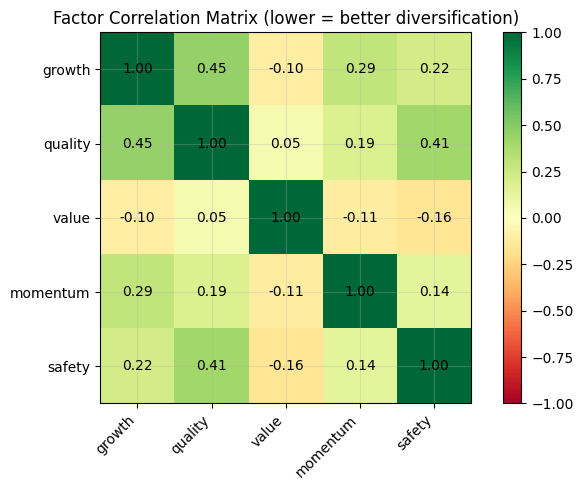

Low off-diagonal values mean each factor adds independent signal ✓


In [13]:
factor_cols = ['f_growth', 'f_quality', 'f_value', 'f_momentum', 'f_safety']
corr = df_fund[factor_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr.values, cmap='RdYlGn', vmin=-1, vmax=1)
plt.colorbar(im)
ax.set_xticks(range(len(factor_cols)))
ax.set_yticks(range(len(factor_cols)))
ax.set_xticklabels([c.replace('f_','') for c in factor_cols], rotation=45, ha='right')
ax.set_yticklabels([c.replace('f_','') for c in factor_cols])

for i in range(len(factor_cols)):
    for j in range(len(factor_cols)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center',
                fontsize=10, color='black')

ax.set_title('Factor Correlation Matrix (lower = better diversification)')
plt.tight_layout()
plt.savefig('factor_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Low off-diagonal values mean each factor adds independent signal ✓')